# Análisis exploratorio de datos (EDA) — Airbnb Bogotá

**Taller 2 · Proceso ETL con los datasets de Airbnb Bogotá, Distrito Capital, Colombia**

Este notebook corresponde a la fase de **comprensión de los datos** previa a la transformación.
Los datos se leen **desde MongoDB** (base `Airbnb`, colecciones `Listings`, `Reviews` y `Calendar`)
usando la clase `Extraccion` de `src/extraccion.py`, no desde los archivos CSV.

**Contenido**

1. Carga de los datos
2. Entendimiento general de los datos (2.1)
3. Calidad de los datos: nulos, duplicados y atípicos (2.2)
4. Exploración de relaciones y distribuciones
5. Posibles transformaciones (2.3)
6. Hallazgos y decisiones para la fase de transformación (2.4)

> Las decisiones de la sección 6 son las que se implementaron en `src/transformacion.py`.

## 1. Carga de los datos

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter

# Permite importar los módulos de src/ sin importar desde dónde se abra el notebook
raiz = Path.cwd().resolve()
if raiz.name == "notebooks":
    raiz = raiz.parent
sys.path.append(str(raiz / "src"))

from extraccion import Extraccion

# --- Estilo de las gráficas: un solo tono (azul) para magnitudes, naranja como segundo color ---
AZUL, NARANJA, ROJO = "#2a78d6", "#eb6834", "#e34948"
TINTA, TINTA_SUAVE, REJILLA = "#0b0b0b", "#52514e", "#e1e0d9"
sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#c3c2b7", "grid.color": REJILLA, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelcolor": TINTA_SUAVE, "text.color": TINTA,
    "xtick.color": TINTA_SUAVE, "ytick.color": TINTA_SUAVE, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
miles = FuncFormatter(lambda v, _: f"{v:,.0f}")

In [2]:
extractor = Extraccion(db_name="Airbnb")
extractor.conectar()
df_listings = extractor.extraer_datos("Listings")
df_reviews = extractor.extraer_datos("Reviews")
df_calendar = extractor.extraer_datos("Calendar")
extractor.cerrar()

2026-10-05 08:56:38 - INFO - [etl.extraccion] Conexión exitosa a MongoDB (localhost:27017), base de datos 'Airbnb'.


2026-10-05 08:56:41 - INFO - [etl.extraccion] Extracción exitosa: 19187 registros y 78 columnas extraídos de la colección 'Listings'.


2026-10-05 08:56:46 - INFO - [etl.extraccion] Extracción exitosa: 527731 registros y 6 columnas extraídos de la colección 'Reviews'.


2026-10-05 08:57:19 - INFO - [etl.extraccion] Extracción exitosa: 7003255 registros y 5 columnas extraídos de la colección 'Calendar'.


2026-10-05 08:57:19 - INFO - [etl.extraccion] Conexión a MongoDB cerrada.


## 2. Entendimiento general de los datos (2.1)

### 2.1.1 Colección `Listings` (anuncios)

In [3]:
print(f"LISTINGS -> {df_listings.shape[0]:,} registros y {df_listings.shape[1]} columnas")
columnas_clave = ["id", "name", "host_id", "host_is_superhost", "neighbourhood_cleansed", "property_type",
                  "room_type", "accommodates", "bedrooms", "beds", "price", "minimum_nights",
                  "availability_365", "number_of_reviews", "review_scores_rating"]
df_listings[columnas_clave].head()

LISTINGS -> 19,187 registros y 78 columnas


,id,name,host_id,host_is_superhost,neighbourhood_cleansed,property_type,room_type,accommodates,bedrooms,beds,price,minimum_nights,availability_365,number_of_reviews,review_scores_rating
0,27841,Rosales Luxury Large 2BR Boutique Apt,113734,True,Chapinero,Entire serviced apartment,Entire home/apt,4,2.00,3.00,"$284,294.01",28.00,82,45,4.87
1,65762,Apartaestudios La Candelaria,321447,True,Candelaria,Entire loft,Entire home/apt,3,1.00,1.00,"$215,000.00",1.00,236,33,4.75
2,138660,Excelent Studio ROSALES/ ZONA G,676823,False,Chapinero,Entire rental unit,Entire home/apt,4,2.00,2.00,"$99,196.10",30.00,303,22,4.43
3,178850,"MODERN APARTMENT, 3 ROOMS, 4 PAX",498646,False,Usaquen,Entire rental unit,Entire home/apt,4,3.00,3.00,"$179,910.67",30.00,353,3,5.00
4,289669,Room near to everything you need in Bogotá!,1503758,True,Teusaquillo,Private room in home,Private room,2,1.00,1.00,"$82,260.75",4.00,222,2,4.50


In [4]:
df_listings.info()

<class 'pandas.DataFrame'>
RangeIndex: 19187 entries, 0 to 19186
Data columns (total 78 columns):
 #   Column                                        Non-Null Count  Dtype         
---  ------                                        --------------  -----         
 0   id                                            19187 non-null  int64         
 1   listing_url                                   19187 non-null  str           
 2   scrape_id                                     19187 non-null  int64         
 3   last_scraped                                  19187 non-null  datetime64[us]
 4   source                                        19187 non-null  str           
 5   name                                          19187 non-null  object        
 6   description                                   18664 non-null  str           
 7   picture_url                                   19187 non-null  str           
 8   host_id                                       19187 non-null  int64         


In [5]:
variables_num = ["accommodates", "bedrooms", "beds", "minimum_nights", "maximum_nights", "availability_365",
                 "number_of_reviews", "review_scores_rating", "reviews_per_month"]
df_listings[variables_num].describe(percentiles=[.25, .5, .75, .95, .99]).T

,count,mean,std,min,25%,50%,75%,95%,99%,max
accommodates,"19,187.00",3.11,2.09,1.00,2.00,2.00,4.00,6.00,14.00,16.00
bedrooms,"16,228.00",1.54,1.60,1.00,1.00,1.00,2.00,3.00,7.00,50.00
beds,"18,896.00",1.95,2.09,1.00,1.00,1.00,2.00,4.00,10.00,50.00
minimum_nights,"19,183.00",6.98,10.99,1.00,1.00,1.00,3.00,30.00,30.00,32.00
maximum_nights,"19,183.00","448,500.35","31,007,553.96",2.00,365.00,365.00,"1,125.00","1,125.00","1,125.00","2,147,483,647.00"
availability_365,"19,187.00",306.95,82.07,0.00,269.00,349.00,363.00,365.00,365.00,365.00
number_of_reviews,"19,187.00",27.50,74.00,0.00,1.00,8.00,31.00,114.00,243.00,"6,162.00"
review_scores_rating,"14,922.00",4.70,0.47,1.00,4.64,4.83,4.98,5.00,5.00,5.00
reviews_per_month,"14,922.00",1.46,2.10,0.01,0.28,0.83,1.93,4.87,8.25,72.61


**Interpretación — Listings**

- Es la tabla principal: **19.187 anuncios** (uno por `id`) y **78 columnas**. De ellas, unas quince se usan directamente
  en el análisis (ubicación, tipo de alojamiento, capacidad, precio, reglas de estancia y reseñas); el resto son URLs,
  identificadores y campos de la consulta de precios (`price_quote_*`).
- **Tipos de dato problemáticos:** `price` llega como **texto** (`"$284,294.01"`), `amenities` como **lista** de Python y
  `price_quote_raw` como **diccionario**. Ninguno se puede guardar tal cual en SQLite ni en Excel ni usar en cálculos.
- **Asimetría fuerte:** `number_of_reviews` tiene mediana 8 pero máximo 6.162 (pocos anuncios concentran las reseñas) y
  `review_scores_rating` tiene media 4,70 y mediana 4,83: las calificaciones se concentran cerca de 5 y casi no discriminan.
- **Reglas de estancia:** la mediana de `minimum_nights` es 1 pero el percentil 95 ya es 30, lo que sugiere dos tipos de
  anuncio (estancias cortas y alquileres mensuales). `maximum_nights` tiene un máximo de **2.147.483.647**, que no es una
  cantidad de noches real (se analiza en la sección 3.3).
- `availability_365` tiene mediana 349: la mayoría de anuncios aparece disponible casi todo el año.

### 2.1.2 Colección `Reviews` (reseñas)

In [6]:
print(f"REVIEWS -> {df_reviews.shape[0]:,} registros y {df_reviews.shape[1]} columnas")
df_reviews.head()

REVIEWS -> 527,731 registros y 6 columnas


,listing_id,id,date,reviewer_id,reviewer_name,comments
0,27841,113163,2010-10-06,121485,Paul,I really enjoyed staying at Marcela's place. I...
1,27841,143106,2010-11-22,288940,Vic,"I, Arrived an hour late from the airport. Mar..."
2,27841,172475,2011-01-19,98406,Matt,"Wonderful hosts, beautiful spacious apartment,..."
3,27841,225796,2011-04-13,471115,Tiffany,Marcela was a lovely and gracious host. She me...
4,27841,952928,2012-02-27,1098411,Sarah,Marcela is the perfect host and has a gorgeuos...


In [7]:
df_reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 527731 entries, 0 to 527730
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   listing_id     527731 non-null  int64         
 1   id             527731 non-null  int64         
 2   date           527731 non-null  datetime64[us]
 3   reviewer_id    527731 non-null  int64         
 4   reviewer_name  527731 non-null  object        
 5   comments       527730 non-null  object        
dtypes: datetime64[us](1), int64(3), object(2)
memory usage: 24.2+ MB


In [8]:
print("Rango de fechas de las reseñas:", df_reviews["date"].min().date(), "->", df_reviews["date"].max().date())
print("Anuncios distintos con reseñas:", f"{df_reviews['listing_id'].nunique():,}")
print("Reseñas por anuncio (descripción):")
df_reviews.groupby("listing_id").size().describe(percentiles=[.5, .95, .99]).to_frame("reseñas_por_anuncio").T

Rango de fechas de las reseñas: 2010-10-06 -> 2026-06-21
Anuncios distintos con reseñas: 14,922
Reseñas por anuncio (descripción):


,count,mean,std,min,50%,95%,99%,max
reseñas_por_anuncio,"14,922.00",35.37,82.24,1.00,15.00,129.00,264.79,"6,162.00"


**Interpretación — Reviews**

- **527.731 reseñas** en 6 columnas. `id` identifica la reseña y `listing_id` la relaciona con `Listings.id` (relación 1 a N).
- Cubre desde **2010-10-06 hasta 2026-06-21**. Solo **14.922 anuncios (77,8 %)** tienen al menos una reseña; el resto (4.265)
  nunca ha recibido una. Ese número reaparece como cantidad de nulos en las columnas de calificación de Listings.
- La mediana es de 15 reseñas por anuncio, pero el percentil 95 es 129 y el máximo 6.162: unos pocos anuncios dominan el volumen.
- `comments` es texto libre; se revisa su limpieza en la sección 4.3.

### 2.1.3 Colección `Calendar` (calendario de disponibilidad)

In [9]:
print(f"CALENDAR -> {df_calendar.shape[0]:,} registros y {df_calendar.shape[1]} columnas")
df_calendar.head()

CALENDAR -> 7,003,255 registros y 5 columnas


,listing_id,date,available,minimum_nights,maximum_nights
0,15410909,2026-06-22,False,2,1125
1,15410909,2026-06-23,False,2,1125
2,15410909,2026-06-24,False,2,1125
3,15410909,2026-06-25,True,2,1125
4,15410909,2026-06-26,True,2,1125


In [10]:
df_calendar.info()

<class 'pandas.DataFrame'>
RangeIndex: 7003255 entries, 0 to 7003254
Data columns (total 5 columns):
 #   Column          Dtype         
---  ------          -----         
 0   listing_id      int64         
 1   date            datetime64[us]
 2   available       bool          
 3   minimum_nights  int64         
 4   maximum_nights  int64         
dtypes: bool(1), datetime64[us](1), int64(3)
memory usage: 220.4 MB


In [11]:
print("Rango de fechas:", df_calendar["date"].min().date(), "->", df_calendar["date"].max().date())
print("Anuncios distintos:", f"{df_calendar['listing_id'].nunique():,}",
      "| días por anuncio:", df_calendar.groupby("listing_id").size().unique())
print("Valores de 'available':", df_calendar["available"].value_counts().to_dict())
df_calendar[["minimum_nights", "maximum_nights"]].describe(percentiles=[.5, .95, .99]).T

Rango de fechas: 2026-06-21 -> 2027-06-21


Anuncios distintos: 19,187 | días por anuncio: [365]
Valores de 'available': {True: 5890813, False: 1112442}


,count,mean,std,min,50%,95%,99%,max
minimum_nights,"7,003,255.00",7.25,11.66,1.00,2.00,30.00,30.00,365.00
maximum_nights,"7,003,255.00","447,784.59","30,982,278.40",1.00,365.00,"1,125.00","1,125.00","2,147,483,647.00"


**Interpretación — Calendar**

- **7.003.255 registros = 19.187 anuncios × 365 días**: hay exactamente un registro por anuncio y día, del
  **2026-06-21 al 2027-06-21**. La cobertura es completa y no faltan días.
- Solo trae `listing_id`, `date`, `available`, `minimum_nights` y `maximum_nights`: **no incluye precio diario**. El único
  precio del proyecto es el de `Listings`, por lo que no se pueden analizar variaciones de precio por fecha.
- **84,1 % de los días figura disponible** (5.890.813) y **15,9 % no disponible** (1.112.442). `available = False` mezcla
  días *reservados* y días *bloqueados por el anfitrión*; con estos datos no se pueden separar, así que "no disponible"
  no equivale exactamente a "ocupado".
- `maximum_nights` también contiene el valor 2.147.483.647 (ver 3.3).

## 3. Calidad de los datos (2.2)

### 3.1 Valores nulos o faltantes por columna

LISTINGS: 34 de 78 columnas tienen nulos


,nulos,porcentaje
host_about,8799,45.86
host_location,5157,26.88
review_scores_checkin,4266,22.23
review_scores_location,4266,22.23
review_scores_value,4266,22.23
last_review,4265,22.23
first_review,4265,22.23
review_scores_accuracy,4265,22.23
review_scores_rating,4265,22.23
review_scores_cleanliness,4265,22.23



REVIEWS: 1 de 6 columnas tienen nulos


,nulos,porcentaje
comments,1,0.00



CALENDAR: 0 de 5 columnas tienen nulos


,nulos,porcentaje


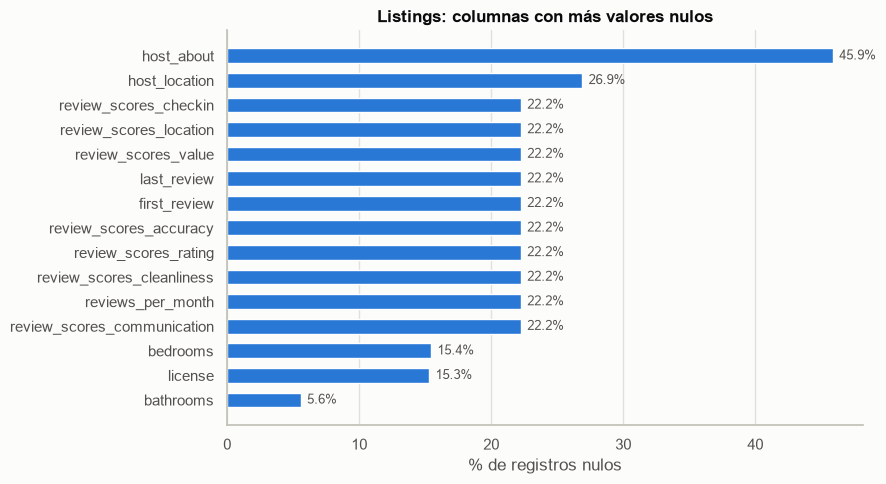

In [12]:
def resumen_nulos(df, nombre):
    nulos = df.isna().sum()
    tabla = pd.DataFrame({"nulos": nulos, "porcentaje": nulos / len(df) * 100})
    tabla = tabla[tabla["nulos"] > 0].sort_values("nulos", ascending=False)
    print(f"{nombre}: {len(tabla)} de {df.shape[1]} columnas tienen nulos")
    return tabla

nulos_listings = resumen_nulos(df_listings, "LISTINGS")
display(nulos_listings.head(15))
print()
display(resumen_nulos(df_reviews, "REVIEWS"))
print()
display(resumen_nulos(df_calendar, "CALENDAR").head())

top = nulos_listings.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top.index, top["porcentaje"], color=AZUL, height=0.6)
ax.set_title("Listings: columnas con más valores nulos")
ax.set_xlabel("% de registros nulos")
ax.grid(axis="y", visible=False)
for y, v in enumerate(top["porcentaje"]):
    ax.text(v + 0.5, y, f"{v:.1f}%", va="center", fontsize=9, color=TINTA_SUAVE)
plt.tight_layout()
plt.show()

**Interpretación — nulos**

34 de las 78 columnas de Listings tienen nulos, pero **no todos significan lo mismo**:

1. **Columnas de reseñas (10 columnas, 22,2 % = 4.265 anuncios):** `review_scores_*`, `first_review`, `last_review` y
   `reviews_per_month`. No son datos perdidos: son anuncios **sin ninguna reseña** (coincide con los 14.922 anuncios con
   reseñas en `Reviews`). **Decisión: no imputar.** Rellenarlos con un promedio inventaría calificaciones que nadie dio.
2. **Texto opcional del anfitrión:** `host_about` (45,9 %) y `host_location` (26,9 %). Decisión: rellenar con `"Sin información"`.
3. **Características físicas:** `bedrooms` (15,4 %), `bathrooms` (5,6 %) y `beds` (1,5 %). Decisión: imputar con la **mediana**
   (robusta a valores extremos; las medianas son 1 habitación y 1 cama). Para baños además existe `bathrooms_text`.
4. **`price` (195 anuncios, 1,0 %):** el precio es la variable central del análisis; un anuncio sin precio no sirve.
   Decisión: **descartar esos registros**.

En `Reviews` solo falta 1 comentario (de 527.731) y `Calendar` no tiene ningún nulo.

**Columnas "vacías" que no son nulos reales.** `host_verifications` no aparece arriba porque no es nula,
pero conviene revisar su contenido real:

In [13]:
print("host_verifications ->", df_listings["host_verifications"].value_counts(dropna=False).to_dict())
print("Tipos de la columna 'amenities':", df_listings["amenities"].map(type).value_counts().to_dict())
print("Tipos de la columna 'price_quote_raw':", df_listings["price_quote_raw"].map(type).value_counts().to_dict())

host_verifications -> {'None': 19187}
Tipos de la columna 'amenities': {<class 'list'>: 19187}
Tipos de la columna 'price_quote_raw': {<class 'dict'>: 19184, <class 'float'>: 3}


**Interpretación — nulos "ocultos"**

`host_verifications` no figura entre los nulos porque sus 19.187 valores son el **texto `'None'`**, no un nulo de verdad.
Es una columna sin información. Decisión: **eliminarla** (`eliminar_columnas_vacias` reconoce `'None'` como vacío).
`amenities` es lista en todos los registros y `price_quote_raw` es diccionario en 19.184 (los otros 3 son nulos).

### 3.2 Registros duplicados

In [14]:
# 'amenities' (listas) y 'price_quote_raw' (diccionarios) no son hasheables: se comparan como texto
dup_listings_filas = df_listings.astype(str).duplicated().sum()
dup_listings_id = df_listings["id"].duplicated().sum()
dup_reviews_filas = df_reviews.duplicated().sum()
dup_reviews_id = df_reviews["id"].duplicated().sum()
dup_calendar_filas = df_calendar.duplicated().sum()
dup_calendar_clave = df_calendar.duplicated(subset=["listing_id", "date"]).sum()

pd.DataFrame({
    "filas completas duplicadas": [dup_listings_filas, dup_reviews_filas, dup_calendar_filas],
    "clave duplicada": [dup_listings_id, dup_reviews_id, dup_calendar_clave],
    "clave utilizada": ["id", "id", "listing_id + date"],
}, index=["Listings", "Reviews", "Calendar"])

,filas completas duplicadas,clave duplicada,clave utilizada
Listings,0,0,id
Reviews,0,0,id
Calendar,0,0,listing_id + date


**Interpretación — duplicados**

No hay duplicados en ninguna colección, ni como fila completa ni por clave (`id` en Listings y Reviews;
`listing_id + date` en Calendar). **Con estos datos no es necesario eliminar registros duplicados.**
Aun así, el ETL conserva la verificación **por clave** (no por fila completa) como control de calidad: si el dataset se
vuelve a descargar o se carga dos veces en MongoDB, los duplicados se detectarían y eliminarían.

### 3.3 Valores atípicos (outliers): `price`, `minimum_nights` y `availability_365`

In [15]:
# El precio llega como texto con símbolos ("$284,294.01"): se convierte solo para este análisis
precio = pd.to_numeric(df_listings["price"].astype(str).str.replace(r"[^\d.]", "", regex=True), errors="coerce")
print(f"Precios nulos/no convertibles: {precio.isna().sum():,} | precios <= 0: {(precio <= 0).sum()}")
print(f"Monedas declaradas en price_quote_raw: "
      f"{df_listings['price_quote_raw'].map(lambda d: d['quote']['currency'] if isinstance(d, dict) and d.get('quote') else None).value_counts().to_dict()}")
precio.describe(percentiles=[.01, .25, .5, .75, .95, .99]).to_frame("price (COP por noche)")

Precios nulos/no convertibles: 195 | precios <= 0: 0
Monedas declaradas en price_quote_raw: {'COP': 18993}


,price (COP por noche)
count,"18,992.00"
mean,"446,026.55"
std,"8,829,056.71"
min,"19,181.11"
1%,"37,610.03"
25%,"110,000.00"
50%,"161,460.00"
75%,"230,346.38"
95%,"497,579.69"
99%,"1,330,087.13"


In [16]:
def atipicos_iqr(serie, factor=1.5):
    q1, q3 = serie.quantile(.25), serie.quantile(.75)
    iqr = q3 - q1
    inf, sup = q1 - factor * iqr, q3 + factor * iqr
    mask = (serie < inf) | (serie > sup)
    return {"Q1": q1, "Q3": q3, "límite inferior": inf, "límite superior": sup,
            "atípicos": int(mask.sum()), "% atípicos": mask.mean() * 100, "máximo": serie.max()}

tabla_atipicos = pd.DataFrame({
    "price": atipicos_iqr(precio.dropna()),
    "minimum_nights": atipicos_iqr(df_listings["minimum_nights"].dropna()),
    "availability_365": atipicos_iqr(df_listings["availability_365"].dropna()),
}).T
tabla_atipicos

,Q1,Q3,límite inferior,límite superior,atípicos,% atípicos,máximo
price,"110,000.00","230,346.38","-70,519.56","410,865.94","1,410.00",7.42,"448,176,567.00"
minimum_nights,1.00,3.00,-2.00,6.00,"4,053.00",21.13,32.00
availability_365,269.00,363.00,128.00,504.00,"1,129.00",5.88,365.00


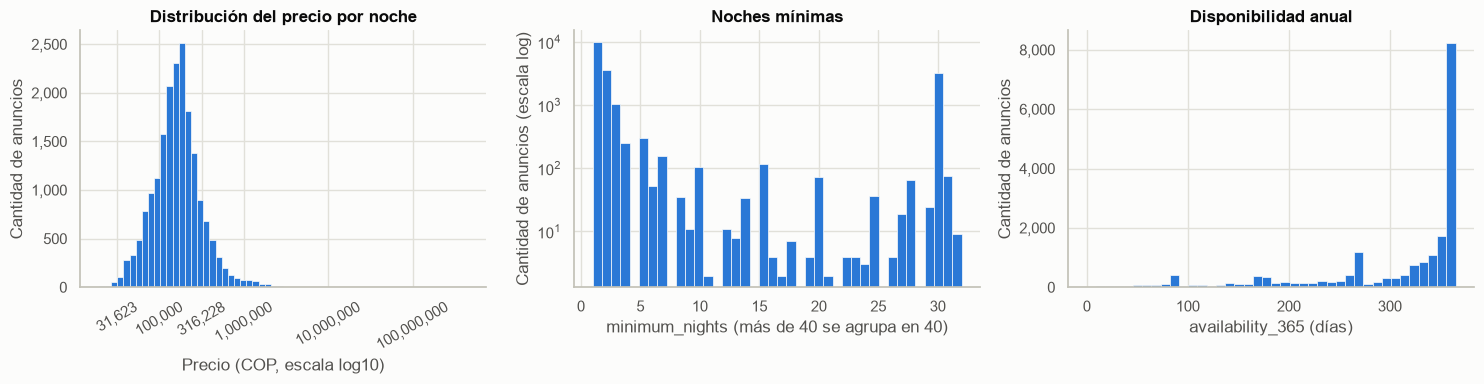

In [17]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))

# Precio: escala logarítmica porque la cola derecha es extrema
ejes[0].hist(np.log10(precio.dropna()), bins=60, color=AZUL, edgecolor="#fcfcfb", linewidth=0.5)
ejes[0].set_title("Distribución del precio por noche")
ejes[0].set_xlabel("Precio (COP, escala log10)")
ejes[0].set_ylabel("Cantidad de anuncios")
ticks = [4.5, 5, 5.5, 6, 7, 8]
ejes[0].set_xticks(ticks)
ejes[0].set_xticklabels([f"{10**t:,.0f}" for t in ticks], rotation=30)
ejes[0].yaxis.set_major_formatter(miles)

ejes[1].hist(df_listings["minimum_nights"].clip(upper=40), bins=40, color=AZUL, edgecolor="#fcfcfb", linewidth=0.5)
ejes[1].set_title("Noches mínimas")
ejes[1].set_xlabel("minimum_nights (más de 40 se agrupa en 40)")
ejes[1].set_yscale("log")
ejes[1].set_ylabel("Cantidad de anuncios (escala log)")

ejes[2].hist(df_listings["availability_365"], bins=40, color=AZUL, edgecolor="#fcfcfb", linewidth=0.5)
ejes[2].set_title("Disponibilidad anual")
ejes[2].set_xlabel("availability_365 (días)")
ejes[2].set_ylabel("Cantidad de anuncios")
ejes[2].yaxis.set_major_formatter(miles)
plt.tight_layout()
plt.show()

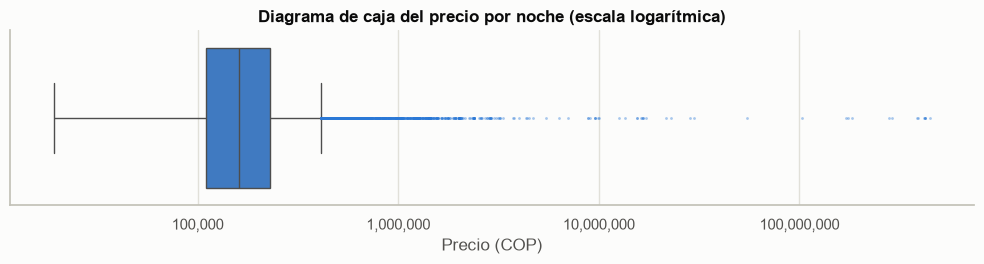

Los 8 precios más altos (COP por noche):


,id,property_type,room_type,accommodates,precio
17185,1629245377389583455,Entire rental unit,Entire home/apt,2,"448,176,567.00"
17227,1631561754372485139,Private room in rental unit,Private room,2,"421,287,834.00"
17238,1632658392056259396,Private room in rental unit,Private room,2,"421,287,834.00"
17240,1632680823682299581,Private room in loft,Private room,4,"421,287,834.00"
17241,1632687908999942806,Private room in rental unit,Private room,2,"418,047,397.00"
17243,1632693865280443336,Private room in rental unit,Private room,2,"388,883,464.00"
17239,1632670566895238267,Private room in rental unit,Private room,2,"385,643,027.00"
6967,872010695106019062,Private room in casa particular,Private room,1,"288,909,191.69"


In [18]:
fig, ax = plt.subplots(figsize=(10, 2.8))
sns.boxplot(x=precio.dropna(), color=AZUL, fliersize=2, linewidth=1, ax=ax,
            flierprops={"markerfacecolor": AZUL, "alpha": 0.4, "markeredgewidth": 0})
ax.set_xscale("log")
ax.xaxis.set_major_formatter(miles)
ax.set_title("Diagrama de caja del precio por noche (escala logarítmica)")
ax.set_xlabel("Precio (COP)")
plt.tight_layout()
plt.show()

print("Los 8 precios más altos (COP por noche):")
df_listings.assign(precio=precio).nlargest(8, "precio")[["id", "property_type", "room_type", "accommodates", "precio"]]

**Interpretación — valores atípicos**

**Precio (`price`).**
- La mediana es **161.460 COP** por noche, pero la media es **446.027 COP** (casi 3 veces mayor): la media está arrastrada
  por valores extremos. El máximo es **448.176.567 COP** por noche.
- Con la regla del IQR hay **1.410 anuncios atípicos (7,4 %)** por encima de ~410.866 COP. No todos son errores: precios entre
  400.000 y 1.000.000 COP son plausibles para propiedades de lujo.
- Los valores más altos **sí parecen errores de captura**: la tabla muestra *habitaciones privadas para 1–4 personas* con precios de
  289 a 448 **millones** de COP por noche, y la mayoría son anuncios con `id` muy grandes (probablemente publicados hace poco). Hay
  38 anuncios sobre 5 millones, 27 sobre 10 millones (unos US$2.500 por noche) y 13 sobre 100 millones.
- En el histograma (escala logarítmica) el grueso de los anuncios se concentra entre ~60.000 y ~400.000 COP, con forma
  aproximadamente log-normal y una cola muy larga a la derecha.
- **Decisión:** no borrar los atípicos con el IQR; **marcarlos** en la columna `precio_atipico` para que el análisis posterior
  decida, y usar la **mediana** en vez de la media al resumir precios.

**Noches mínimas (`minimum_nights`).** La distribución es **bimodal**: 14.528 anuncios (75,7 %) piden 1 a 3 noches y hay un pico
enorme en **30 noches** (3.240 anuncios) con picos menores en números redondos (7, 10, 15, 20). El IQR marca 4.053 anuncios (21 %) como
atípicos, pero **no son errores**: son alquileres mensuales, un segmento distinto del mercado.

**Disponibilidad (`availability_365`).** Rango válido (0 a 365). La mayoría de anuncios está disponible casi todo el año:
3.508 (18,3 %) figuran con 365 días y solo 4 con 0. Los 1.129 atípicos del IQR (5,9 %) son anuncios con menos de 128 días
disponibles, es decir, muy reservados o bloqueados; tampoco son errores.

In [19]:
print("maximum_nights -> valores más altos:", df_listings["maximum_nights"].nlargest(5).tolist())
print("Anuncios con minimum_nights > 30:", (df_listings["minimum_nights"] > 30).sum(),
      "| >= 28:", (df_listings["minimum_nights"] >= 28).sum())
print("Anuncios con availability_365 = 0:", (df_listings["availability_365"] == 0).sum(),
      "| = 365:", (df_listings["availability_365"] == 365).sum())

maximum_nights -> valores más altos: [2147483647.0, 2147483647.0, 2147483647.0, 2147483647.0, 1241244.0]
Anuncios con minimum_nights > 30: 84 | >= 28: 3414
Anuncios con availability_365 = 0: 4 | = 365: 3508


**Interpretación — valor centinela en `maximum_nights`**

6 anuncios superan las 1.125 noches (el máximo que Airbnb permite reservar), cuatro de ellos con **2.147.483.647**, que es el mayor
entero de 32 bits, es decir, un valor "sin límite" y no una cantidad real. También aparece en `Calendar.maximum_nights`.
**Decisión:** limitar estos valores a 1.125 (`limitar_valores`). Además, por la bimodalidad de `minimum_nights` se crea la bandera
`estadia_larga` (28 noches o más: 3.414 anuncios en los datos originales y 3.336 tras descartar los anuncios sin precio) para analizar ese segmento por separado.

## 4. Distribuciones y relaciones relevantes

### 4.1 Oferta por zona y tipo de alojamiento

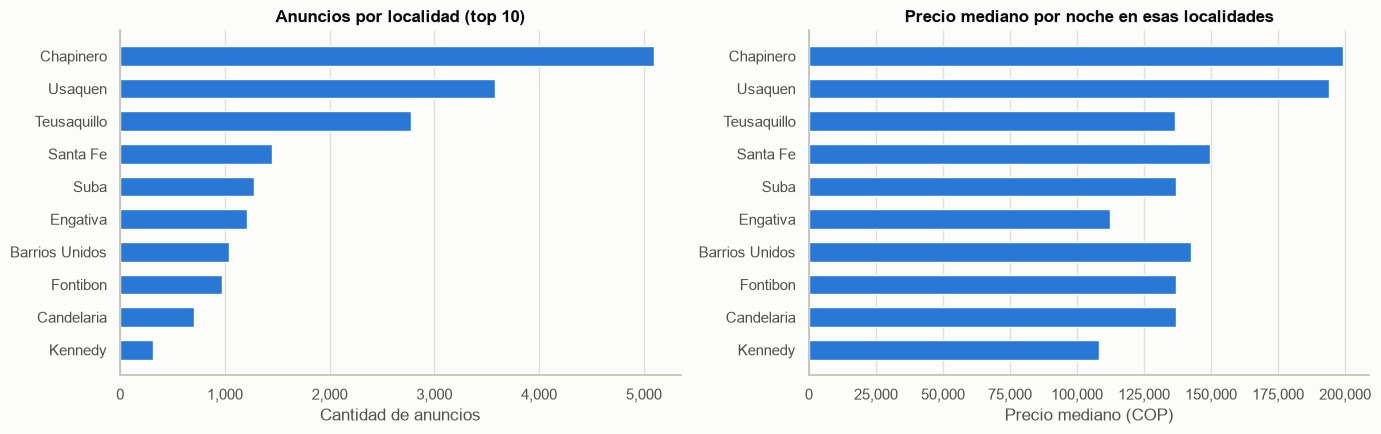

room_type  Entire home/apt  Private room  Shared room  Hotel room
anuncios             13865          5172          117          33


In [20]:
datos = df_listings.assign(precio=precio)
top_barrios = datos["neighbourhood_cleansed"].value_counts().head(10)
precio_barrio = datos.groupby("neighbourhood_cleansed")["precio"].median().loc[top_barrios.index]

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
orden = top_barrios.index[::-1]
ejes[0].barh(orden, top_barrios.loc[orden], color=AZUL, height=0.6)
ejes[0].set_title("Anuncios por localidad (top 10)")
ejes[0].set_xlabel("Cantidad de anuncios")
ejes[0].xaxis.set_major_formatter(miles)
ejes[0].grid(axis="y", visible=False)

ejes[1].barh(orden, precio_barrio.loc[orden], color=AZUL, height=0.6)
ejes[1].set_title("Precio mediano por noche en esas localidades")
ejes[1].set_xlabel("Precio mediano (COP)")
ejes[1].xaxis.set_major_formatter(miles)
ejes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

print(datos["room_type"].value_counts().to_frame("anuncios").T.to_string())

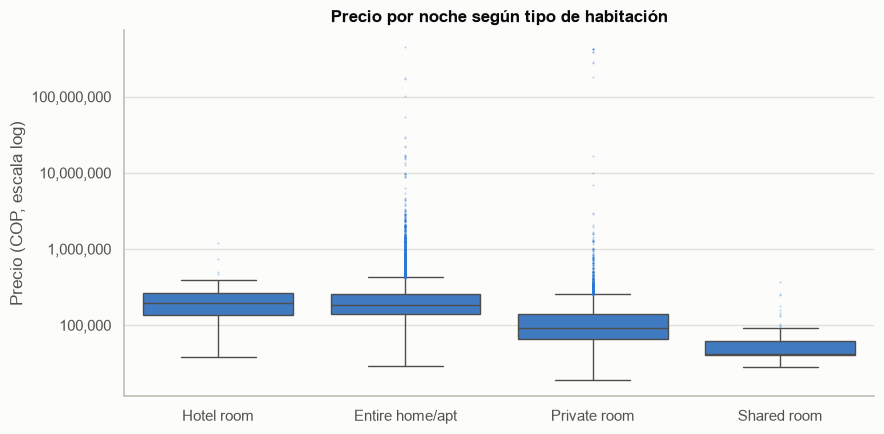

,count,median,mean
room_type,,,
Hotel room,33,"193,048.00","253,385.40"
Entire home/apt,13744,"182,589.00","333,541.96"
Private room,5098,"91,295.00","759,384.92"
Shared room,117,"41,453.00","60,082.24"


In [21]:
fig, ax = plt.subplots(figsize=(9, 4.5))
orden_tipos = datos.groupby("room_type")["precio"].median().sort_values(ascending=False).index
sns.boxplot(data=datos, x="room_type", y="precio", order=orden_tipos, color=AZUL, fliersize=1.5, linewidth=1,
            flierprops={"markerfacecolor": AZUL, "alpha": 0.3, "markeredgewidth": 0}, ax=ax)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(miles)
ax.set_title("Precio por noche según tipo de habitación")
ax.set_xlabel("")
ax.set_ylabel("Precio (COP, escala log)")
plt.tight_layout()
plt.show()
datos.groupby("room_type")["precio"].agg(["count", "median", "mean"]).sort_values("median", ascending=False)

**Interpretación — oferta, precio y tipo de alojamiento**

- **Concentración geográfica:** Chapinero (5.097), Usaquén (3.582) y Teusaquillo (2.779) reúnen **~60 %** de todos los anuncios.
- **Oferta no implica precio alto:** Chapinero y Usaquén tienen además los precios medianos más altos (~199.000 y ~194.000 COP),
  pero **Teusaquillo**, tercera en oferta, tiene un precio mediano bajo (~136.000 COP), similar al de Suba, Fontibón o La Candelaria.
  Kennedy y Engativá son las localidades más económicas (~108.000 y ~112.000 COP).
- **Tipo de habitación:** el 72,3 % de la oferta es *vivienda completa* (13.865) y el 27,0 % *habitación privada* (5.172);
  *habitación compartida* (117) y *hotel* (33) son menos del 1 %, por lo que sus resultados son poco confiables.
- **Los precios extremos se concentran en las habitaciones privadas:** su mediana es 91.295 COP pero su media es 759.385 COP
  (8 veces más). Eso confirma que los valores de cientos de millones son errores y no lujo real: una habitación privada no puede
  valer más que una casa completa.

### 4.2 Correlaciones

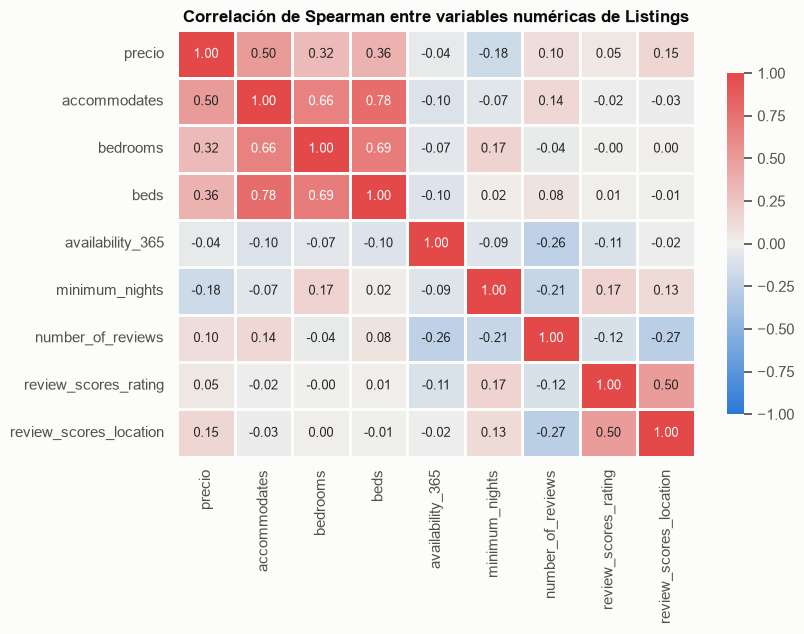

,correlación con precio
accommodates,0.50
beds,0.36
bedrooms,0.32
review_scores_location,0.15
number_of_reviews,0.10
review_scores_rating,0.05
availability_365,-0.04
minimum_nights,-0.18


In [22]:
variables_corr = ["precio", "accommodates", "bedrooms", "beds", "availability_365", "minimum_nights",
                  "number_of_reviews", "review_scores_rating", "review_scores_location"]
corr = datos[variables_corr].corr(method="spearman")   # Spearman: robusta a los valores extremos del precio

mapa = LinearSegmentedColormap.from_list("div", [AZUL, "#f0efec", ROJO])
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=mapa, vmin=-1, vmax=1, center=0, linewidths=1,
            linecolor="#fcfcfb", cbar_kws={"shrink": 0.8}, annot_kws={"size": 9}, ax=ax)
ax.set_title("Correlación de Spearman entre variables numéricas de Listings")
plt.tight_layout()
plt.show()
corr["precio"].drop("precio").sort_values(ascending=False).to_frame("correlación con precio")

**Interpretación — correlaciones** (Spearman, porque es robusta a los valores extremos del precio)

- **El precio sube con la capacidad:** `accommodates` (0,50) es la variable más asociada, seguida de `beds` (0,36) y `bedrooms` (0,32).
- **Estancias largas, menor precio por noche:** `minimum_nights` tiene correlación negativa (−0,18), coherente con los descuentos por
  alquiler mensual.
- **Calidad percibida y precio casi no se relacionan:** calificación (0,05) y número de reseñas (0,10). Las calificaciones están
  tan concentradas cerca de 5 que no explican el precio.
- **Colinealidad:** `accommodates`, `beds` y `bedrooms` están muy correlacionadas entre sí (0,66 a 0,78); si se construye un modelo, no
  conviene usar las tres juntas.
- Los anuncios con más reseñas tienen menos días disponibles (−0,26 con `availability_365`): se reservan más.

### 4.3 Reseñas en el tiempo

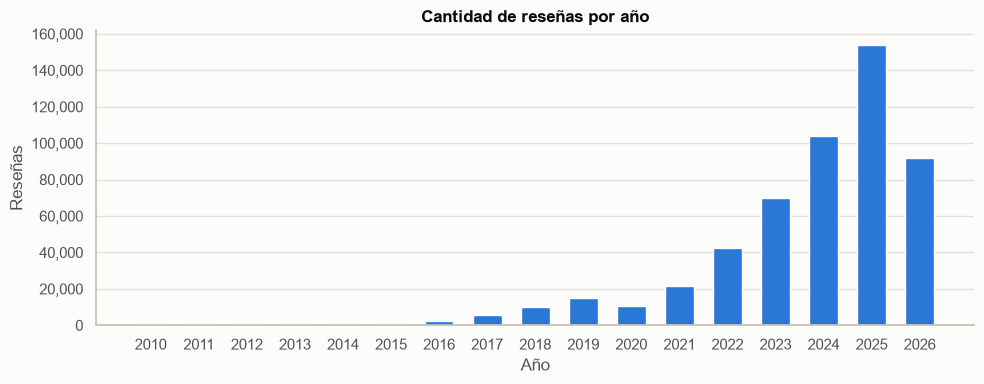

Comentarios con etiquetas HTML (<br/>): 69,375 (13.1%)
Comentarios nulos: 1
Muestra de comentario con HTML:
I really enjoyed staying at Marcela's place. It is a very nice, very large place that can't be better located. You can walk over to Zona G, which is the area in Bogota most noted for restaurants and cafes. You are also a 5 minute cab ride to the Zona


In [23]:
resenas_anio = df_reviews.groupby(df_reviews["date"].dt.year).size()
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(resenas_anio.index.astype(str), resenas_anio.values, color=AZUL, width=0.6)
ax.set_title("Cantidad de reseñas por año")
ax.set_xlabel("Año")
ax.set_ylabel("Reseñas")
ax.yaxis.set_major_formatter(miles)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

comentarios = df_reviews["comments"].astype(str)
print("Comentarios con etiquetas HTML (<br/>):", f"{comentarios.str.contains('<br', regex=False).sum():,}",
      f"({comentarios.str.contains('<br', regex=False).mean() * 100:.1f}%)")
print("Comentarios nulos:", df_reviews["comments"].isna().sum())
print("Muestra de comentario con HTML:")
print(comentarios[comentarios.str.contains("<br", regex=False)].iloc[0][:250])

**Interpretación — reseñas en el tiempo**

- Las reseñas crecen de forma sostenida: casi no hay antes de 2016 y se llega a **~153.000 en 2025**. 2026 solo llega hasta junio
  (~91.000), por lo que va en ritmo superior al de 2025.
- **Caída en 2020** (~10.000 frente a ~14.500 en 2019), coherente con la pandemia, y recuperación desde 2021.
- Hay poca historia antes de 2016, probablemente porque el dataset solo incluye reseñas de anuncios que **siguen activos** hoy
  (los anuncios antiguos dados de baja no aparecen); con estos datos no se puede confirmar.
- **Calidad del texto:** **69.375 comentarios (13,1 %)** contienen etiquetas HTML como `<br/>` y 1 comentario es nulo. Hay que
  limpiar el HTML para que el texto sea legible en Excel y utilizable en análisis de texto.

### 4.4 Disponibilidad en el calendario: agrupación por mes

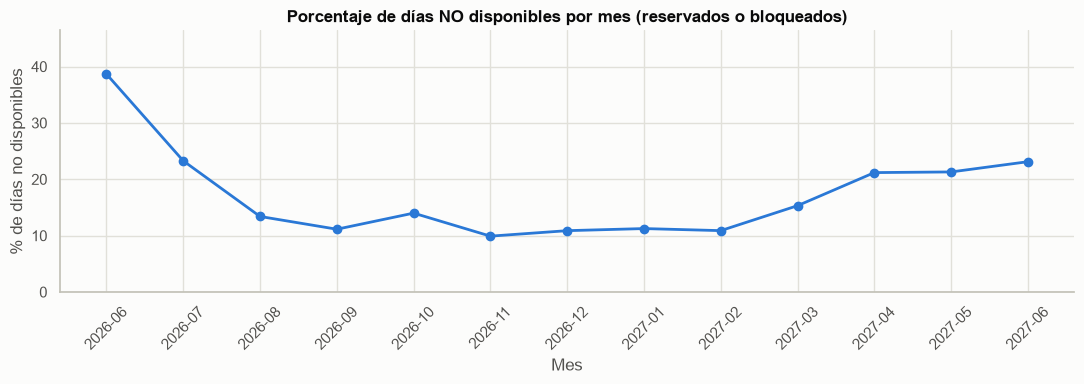

periodo,2026-06,2026-07,2026-08,2026-09,2026-10,2026-11,2026-12,2027-01,2027-02,2027-03,2027-04,2027-05,2027-06
dias,"174,141","594,797","594,797","575,610","594,797","575,610","594,797","594,797","537,236","594,797","575,610","594,797","401,469"
pct_no_disponible,38.66,23.27,13.40,11.14,13.99,9.91,10.88,11.25,10.89,15.31,21.18,21.30,23.12


In [24]:
calendario_mes = (df_calendar.assign(periodo=df_calendar["date"].dt.to_period("M"))
                  .groupby("periodo")["available"]
                  .agg(dias="size", pct_no_disponible=lambda s: (~s).mean() * 100))
calendario_mes.index = calendario_mes.index.astype(str)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(calendario_mes.index, calendario_mes["pct_no_disponible"], color=AZUL, linewidth=2, marker="o", markersize=6)
ax.set_title("Porcentaje de días NO disponibles por mes (reservados o bloqueados)")
ax.set_xlabel("Mes")
ax.set_ylabel("% de días no disponibles")
ax.tick_params(axis="x", rotation=45)
ax.set_ylim(0, max(calendario_mes["pct_no_disponible"]) * 1.2)
plt.tight_layout()
plt.show()
calendario_mes.assign(dias=calendario_mes["dias"].map("{:,}".format)).T

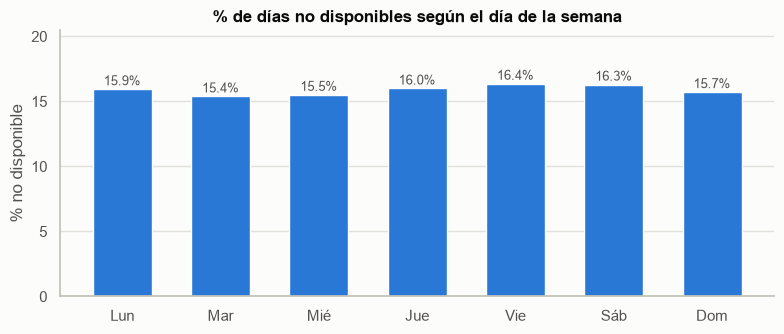

In [25]:
por_dia = df_calendar.groupby(df_calendar["date"].dt.dayofweek)["available"].apply(lambda s: (~s).mean() * 100)
nombres = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(nombres, por_dia.values, color=AZUL, width=0.6)
ax.set_title("% de días no disponibles según el día de la semana")
ax.set_ylabel("% no disponible")
ax.set_ylim(0, por_dia.max() * 1.25)
ax.grid(axis="x", visible=False)
for i, v in enumerate(por_dia.values):
    ax.text(i, v + 0.3, f"{v:.1f}%", ha="center", fontsize=9, color=TINTA_SUAVE)
plt.tight_layout()
plt.show()

**Interpretación — disponibilidad por mes**

- El porcentaje de días **no disponibles** parte en **38,7 %** (junio de 2026, solo los últimos ~9 días del mes), baja a 23,3 % en julio y toca
  fondo en noviembre (**9,9 %**); se mantiene alrededor de 11 % entre diciembre y febrero y **vuelve a subir** hasta ~21–23 %
  entre abril y junio de 2027.
- La curva refleja sobre todo el **horizonte de reserva**: los días más próximos ya están reservados, y a medida que se
  mira más lejos hay menos reservas. **No debe leerse como estacionalidad** (que diciembre parezca poco ocupado se debe a que aún
  no se ha reservado). El repunte final podría deberse a bloqueos de los anfitriones, pero estos datos no permiten confirmarlo.
- Por **día de la semana** casi no hay diferencia (15,4 % a 16,4 %), así que `dia_semana` aporta poca información en este calendario.
- Como el calendario es una **única fotografía** (21-jun-2026), `porcentaje_ocupacion` en el resumen mensual debe leerse como un
  *indicador de no disponibilidad*, no como ocupación real.

## 5. Posibles transformaciones (2.3)

### 5.1 Campos complejos o anidados

In [26]:
muestra_amenities = df_listings["amenities"].iloc[0]
print("Ejemplo de 'amenities' (lista de Python):", muestra_amenities[:6], "...")
cantidad = df_listings["amenities"].map(len)
print(f"Amenidades por anuncio -> mínimo {cantidad.min()}, mediana {cantidad.median():.0f}, máximo {cantidad.max()}")

todas = pd.Series([a for lista in df_listings["amenities"] for a in lista]).value_counts()
print("\nLas 12 amenidades más frecuentes:")
(todas.head(12) / len(df_listings) * 100).round(1).to_frame("% de anuncios que la ofrecen")

Ejemplo de 'amenities' (lista de Python): ['Blender', 'Luggage dropoff allowed', 'Long term stays allowed', 'Children’s dinnerware', 'Drying rack for clothing', 'Free parking on premises'] ...
Amenidades por anuncio -> mínimo 0, mediana 26, máximo 90

Las 12 amenidades más frecuentes:


,% de anuncios que la ofrecen
Wifi,93.40
Kitchen,87.80
Hot water,73.40
TV,70.80
Dedicated workspace,69.40
Hangers,68.00
Dishes and silverware,62.70
Cooking basics,61.80
Iron,61.30
Bed linens,57.20


In [27]:
print("Información del host disponible en Listings:",
      [c for c in df_listings.columns if c.startswith("host_") or c.startswith("hosts_")])
print("\nEjemplo de price_quote_raw (diccionario anidado):")
print(list(df_listings["price_quote_raw"].iloc[0]["quote"].keys()))

Información del host disponible en Listings: ['host_id', 'host_url', 'host_profile_id', 'host_profile_url', 'host_name', 'hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_location', 'host_about', 'host_is_superhost', 'host_picture_url', 'host_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified']

Ejemplo de price_quote_raw (diccionario anidado):
['taxes', 'currency', 'date_match', 'service_fee', 'total_price', 'cleaning_fee', 'is_available', 'discount_amount', 'price_per_night', 'nightly_subtotal', 'discounted_subtotal', 'raw_price_line_items', 'returned_checkin_date', 'requested_checkin_date', 'returned_checkout_date', 'requested_checkout_date']


**Interpretación — campos anidados**

- **`amenities`:** lista de 0 a 90 elementos por anuncio (mediana 26). Wifi (93,4 %) y cocina (87,8 %) son casi universales, por lo que
  aportan poca diferencia; otras como aire acondicionado, estacionamiento o piscina discriminan más. **Decisión:** convertir la lista a
  texto separado por comas, crear `cantidad_amenities` y columnas 1/0 para las amenidades clave (`expandir_amenidades`).
- **Información del host:** hay 17 columnas (`host_*`, `hosts_time_*`). Las útiles son `host_is_superhost` (32,9 % de los anuncios, 6.310),
  `host_identity_verified` y `host_listings_count`. `host_verifications` es inutilizable (todo `'None'`) y `host_about` tiene 45,9 % de nulos.
  **Decisión:** conservar las columnas útiles con tipo numérico y eliminar `host_verifications`.
- **`price_quote_raw`:** diccionario con 16 claves, incluida una lista de líneas de precio. Casi todo duplica columnas planas
  (`price_quote_total_price`, `price_quote_price_per_night`; el precio por noche coincide con `price`). Lo único nuevo es la **moneda**
  (`COP` en todos los anuncios). **Decisión:** extraer `moneda` y descartar el diccionario.

### 5.2 Agrupar o resumir datos

In [28]:
resumen_mensual = (df_calendar.assign(anio=df_calendar["date"].dt.year, mes=df_calendar["date"].dt.month)
                   .groupby(["listing_id", "anio", "mes"], as_index=False)
                   .agg(dias_totales=("available", "size"), dias_disponibles=("available", "sum")))
print(f"Calendar original: {len(df_calendar):,} filas  ->  resumen por anuncio y mes: {len(resumen_mensual):,} filas "
      f"({len(df_calendar) / len(resumen_mensual):.0f} veces menos)")
resumen_mensual.head()

Calendar original: 7,003,255 filas  ->  resumen por anuncio y mes: 249,431 filas (28 veces menos)


,listing_id,anio,mes,dias_totales,dias_disponibles
0,27841,2026,6,9,0
1,27841,2026,7,31,0
2,27841,2026,8,31,0
3,27841,2026,9,30,0
4,27841,2026,10,31,0


**Interpretación — agrupación del calendario**

`Calendar` tiene un registro por anuncio y día. Resumido por **anuncio y mes** queda en 249.431 filas (**28 veces menos**) y se conserva
lo útil: días totales, días disponibles y no disponibles. **Decisión:** generar la tabla `Calendar_Mensual`, que sí cabe en un
Excel (el límite es 1.048.576 filas), y mantener la tabla diaria completa en SQLite.

### 5.3 Estandarización de formatos (fecha, moneda y texto)

In [29]:
print("MONEDA  -> price es texto:", df_listings["price"].map(type).unique(), "| ejemplos:", df_listings["price"].head(3).tolist())
print("FECHAS  -> tipos actuales:",
      {c: str(df_listings[c].dtype) for c in ["last_scraped", "first_review", "last_review"]},
      "| Calendar.date:", str(df_calendar["date"].dtype), "| Reviews.date:", str(df_reviews["date"].dtype))
print("FECHAS  -> ¿tienen hora distinta de 00:00? Calendar:", (df_calendar["date"].dt.hour != 0).any(),
      "| Reviews:", (df_reviews["date"].dt.hour != 0).any())
print("BOOLEANOS -> tipos:", {c: str(df_listings[c].dtype) for c in ["host_is_superhost", "host_identity_verified"]})

texto = df_listings["neighbourhood_cleansed"]
print("TEXTO   -> espacios sobrantes en 'neighbourhood_cleansed':", (texto != texto.str.strip()).sum(),
      "| en 'name':", (df_listings["name"] != df_listings["name"].str.strip()).sum())
print("TEXTO   -> descripciones con HTML:", df_listings["description"].astype(str).str.contains("<br", regex=False).sum())
print("BAÑOS   -> ejemplos de bathrooms_text:", df_listings["bathrooms_text"].dropna().unique()[:6].tolist(),
      "| columna 'bathrooms' nula en", df_listings["bathrooms"].isna().sum(), "anuncios")

MONEDA  -> price es texto: [<class 'str'> <class 'float'>] | ejemplos: ['$284,294.01', '$215,000.00', '$99,196.10']
FECHAS  -> tipos actuales: {'last_scraped': 'datetime64[us]', 'first_review': 'datetime64[us]', 'last_review': 'datetime64[us]'} | Calendar.date: datetime64[us] | Reviews.date: datetime64[us]


FECHAS  -> ¿tienen hora distinta de 00:00? Calendar: False | Reviews: False
BOOLEANOS -> tipos: {'host_is_superhost': 'bool', 'host_identity_verified': 'bool'}


TEXTO   -> espacios sobrantes en 'neighbourhood_cleansed': 0 | en 'name': 4
TEXTO   -> descripciones con HTML: 8045
BAÑOS   -> ejemplos de bathrooms_text: ['2.5 baths', '1 bath', '2 baths', '1 private bath', '1.5 baths', '1 shared bath'] | columna 'bathrooms' nula en 1066 anuncios


**Interpretación — estandarización**

- **Moneda:** `price` es texto con `$` y `,`. Todos los precios están en **COP** (según `price_quote_raw`), así que solo hace falta
  convertirlos a número; no se requiere conversión de divisa. Por estar en pesos y con cola extrema, los rangos de precio se definirán
  por **cuartiles** y no con cortes fijos pensados para dólares.
- **Fechas:** ya llegan como fecha y sin hora, pero se estandarizan a `YYYY-MM-DD` y de `Calendar.date` y `Reviews.date` se derivan
  `anio`, `mes`, `dia`, `trimestre` y `dia_semana`.
- **Booleanos:** vienen como `True/False`; se guardan como 1/0, que SQLite y Excel manejan sin ambigüedad.
- **Texto:** 4 nombres con espacios sobrantes y **8.045 descripciones** con etiquetas HTML (además de los comentarios de reseñas).
  Se limpian espacios y HTML.
- **Baños:** `bathrooms` es nulo en 1.066 anuncios, pero `bathrooms_text` ("2.5 baths", "1 shared bath") sí existe;
  se deriva una columna numérica `banos`.

## 6. Hallazgos y decisiones para la fase de transformación (2.4)

### 6.1 Calidad general de los datos

Los datos son de **buena calidad estructural**: sin duplicados, `Calendar` completo (365 días × 19.187 anuncios) y claves consistentes entre
colecciones. Los problemas se concentran en **el precio** (formato de texto, nulos, valores extremos), **valores centinela**
(`maximum_nights`), **campos anidados** y **texto con HTML**. Además hay limitaciones de contenido: `Calendar` no trae precio diario y
`available` no distingue reservas de bloqueos.

### 6.2 Decisiones para la fase de transformación

| # | Hallazgo (sección) | Decisión | Método en `transformacion.py` |
|---|---|---|---|
| 1 | `price` es texto con `$` y `,` (2.1, 5.3) | Convertir a número | `normalizar_precios` |
| 2 | 195 precios nulos, 1 % (3.1) | Descartar esos registros | `limpiar_nulos_duplicados` |
| 3 | Precios extremos (hasta 448 M COP) y 7,4 % atípicos (3.3) | Marcar sin eliminar; usar mediana | `marcar_atipicos` (`precio_atipico`) |
| 4 | Precio en COP con cola muy larga (3.3, 5.3) | Rangos por **cuartiles** | `categorizar_precios` (`rango_precio`) |
| 5 | Sin duplicados (3.2) | Mantener el control por clave | `limpiar_nulos_duplicados` |
| 6 | Nulos de reseñas = anuncios sin reseñas (3.1) | **No imputar** | `imputar_nulos` (excluye `review_scores_*`) |
| 7 | Texto opcional nulo (`host_about`, ...) (3.1) | `"Sin información"` | `imputar_nulos` |
| 8 | `bedrooms`, `beds`, `bathrooms` nulos (3.1) | Mediana | `imputar_nulos` |
| 9 | `host_verifications` solo contiene `'None'` (3.1) | Eliminar la columna | `eliminar_columnas_vacias` |
| 10 | `amenities` es una lista (5.1) | Texto + conteo + columnas 1/0 | `desanidar_campos`, `expandir_amenidades` |
| 11 | `price_quote_raw` es un diccionario (5.1) | Extraer `moneda`, descartar el resto | `desanidar_diccionario` |
| 12 | Baños solo como texto (5.3) | Derivar `banos` numérico | `extraer_banos` |
| 13 | `maximum_nights = 2.147.483.647` (3.3) | Limitar a 1.125 | `limitar_valores` |
| 14 | `minimum_nights` bimodal (3.3) | Bandera `estadia_larga` | `marcar_estadias_largas` |
| 15 | Booleanos `True/False` (5.3) | 1 / 0 | `normalizar_booleanos` |
| 16 | Fechas sin variables de tiempo (5.3) | Estandarizar `YYYY-MM-DD` y derivar año, mes, día, trimestre, día de semana | `transformar_fechas` |
| 17 | HTML en comentarios y descripciones (4.3, 5.3) | Quitar etiquetas y espacios | `estandarizar_texto` |
| 18 | `Calendar` (7 M filas) no cabe en Excel (5.2) | Resumen mensual por anuncio | `agrupar_calendario_mensual` |

### 6.3 Utilidad y limitaciones

- **Útil para:** analizar oferta y precios por localidad y tipo de alojamiento, segmentar el mercado (estadía corta vs. mensual, rangos de
  precio) y estudiar la evolución de las reseñas.
- **Limitaciones:** el calendario es una sola fotografía y no incluye precio diario; "no disponible" mezcla reservas y bloqueos;
  los precios extremos requieren filtrar con `precio_atipico` antes de promediar; y algunos grupos (habitación compartida, hotel)
  tienen muy pocos anuncios.